<a href="https://colab.research.google.com/github/sawantarya232-blip/Deep-Learning/blob/main/Assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import time
import gc

from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights, ViT_B_16_Weights
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [2]:
# 1. Define Image Transformations
# We need to resize CIFAR-10 images (typically 32x32) to 224x224 to match the expected input size of ResNet and ViT.
# We then convert images to PyTorch Tensors and normalize them using the ImageNet mean and standard deviation.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Download and Load the CIFAR-10 Dataset
# We download the training and testing datasets from PyTorch's built-in datasets library and apply our transforms.
train_data = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# 3. Set Random Seed for Reproducibility
# Setting a manual seed ensures that the random split yields the exact same subsets every time the code runs.
torch.manual_seed(42)

# 4. Select Subsets of the Data
# Since CIFAR-10 is large (50,000 train, 10,000 test), we take a smaller subset (2,000 train, 500 test) to speed up training.
train_indices = torch.randperm(len(train_data))[:2000].tolist()
test_indices = torch.randperm(len(test_data))[:500].tolist()

train_subset = Subset(train_data, train_indices)
test_subset = Subset(test_data, test_indices)

# 5. Create DataLoaders
# DataLoaders help us load the data in batches, shuffle it, and handle multi-processing using CPU/GPU memory optimizations.
train_loader = DataLoader(
    train_subset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_subset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Get the list of human-readable class names (e.g., 'airplane', 'automobile', etc.)
classes = train_data.classes

# Print dataset stats
print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))
print("Classes:", classes)

100%|██████████| 170M/170M [42:02<00:00, 67.6kB/s]


Training images: 2000
Testing images: 500
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


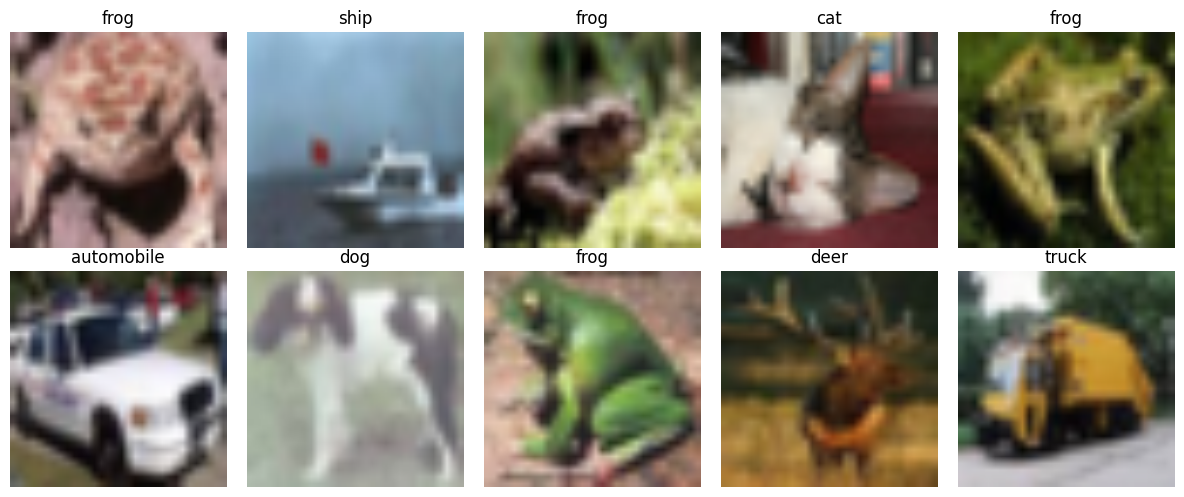

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array([0.229, 0.224, 0.225])
    img = img + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
cnn_model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

for param in cnn_model.parameters():
    param.requires_grad = False

cnn_model.fc = nn.Linear(cnn_model.fc.in_features, 10)

cnn_model = cnn_model.to(device)

print(cnn_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 104MB/s]


Linear(in_features=512, out_features=10, bias=True)


In [5]:
vit_model = models.vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

for param in vit_model.parameters():
    param.requires_grad = False

vit_model.heads.head = nn.Linear(
    vit_model.heads.head.in_features, 10
)

vit_model = vit_model.to(device)

print(vit_model.heads.head)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 176MB/s]


Linear(in_features=768, out_features=10, bias=True)


In [6]:
def train_model(model, train_loader, epochs=2):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    history = {"loss": [], "accuracy": []}
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss / total
        epoch_acc = 100 * correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_acc:.2f}%"
        )

    training_time = time.time() - start_time
    return history, training_time

In [7]:
cnn_history, cnn_time = train_model(
    cnn_model, train_loader, epochs=2
)

print("CNN training time:", round(cnn_time, 2), "seconds")

Epoch 1/2 | Loss: 1.7221 | Accuracy: 42.65%
Epoch 2/2 | Loss: 1.0816 | Accuracy: 68.25%
CNN training time: 11.73 seconds


In [8]:
vit_history, vit_time = train_model(
    vit_model, train_loader, epochs=2
)

print("ViT training time:", round(vit_time, 2), "seconds")

Epoch 1/2 | Loss: 0.6444 | Accuracy: 84.45%
Epoch 2/2 | Loss: 0.2140 | Accuracy: 94.50%
ViT training time: 133.78 seconds


In [9]:
def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predictions.cpu().numpy())

    accuracy = 100 * correct / total
    return accuracy, all_labels, all_preds


cnn_acc, cnn_labels, cnn_preds = evaluate_model(
    cnn_model, test_loader
)

vit_acc, vit_labels, vit_preds = evaluate_model(
    vit_model, test_loader
)

print(f"CNN Test Accuracy: {cnn_acc:.2f}%")
print(f"ViT Test Accuracy: {vit_acc:.2f}%")

CNN Test Accuracy: 73.40%
ViT Test Accuracy: 93.20%


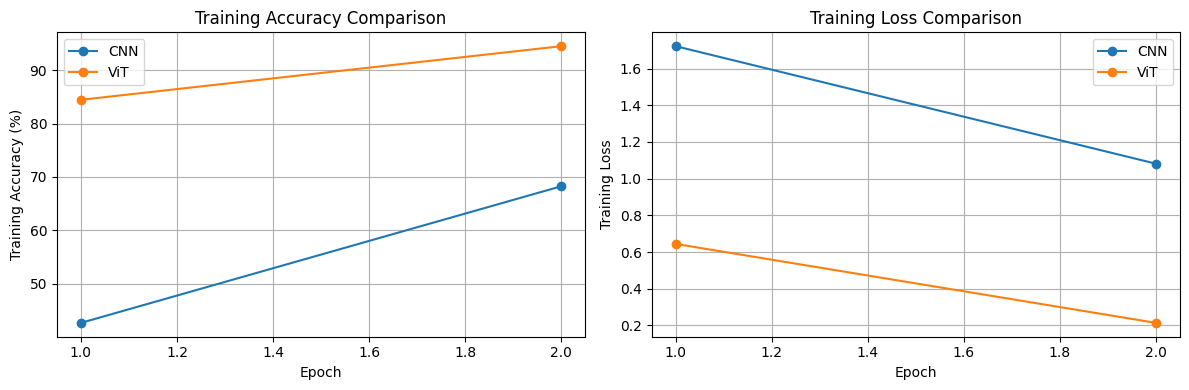

In [10]:
epochs = range(1, 3)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, cnn_history["accuracy"], marker="o", label="CNN")
plt.plot(epochs, vit_history["accuracy"], marker="o", label="ViT")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy Comparison")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, cnn_history["loss"], marker="o", label="CNN")
plt.plot(epochs, vit_history["loss"], marker="o", label="ViT")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

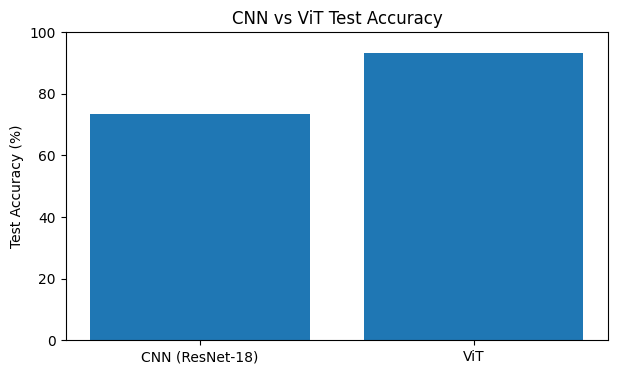

CNN (ResNet-18): Accuracy = 73.40%, Time = 11.73 seconds
ViT: Accuracy = 93.20%, Time = 133.78 seconds


In [11]:
models_names = ["CNN (ResNet-18)", "ViT"]
accuracies = [cnn_acc, vit_acc]
times = [cnn_time, vit_time]

plt.figure(figsize=(7, 4))
plt.bar(models_names, accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs ViT Test Accuracy")
plt.ylim(0, 100)
plt.show()

for name, acc, t in zip(models_names, accuracies, times):
    print(f"{name}: Accuracy = {acc:.2f}%, Time = {t:.2f} seconds")

In [12]:
print("CNN Classification Report")
print(classification_report(
    cnn_labels, cnn_preds,
    labels=list(range(10)),
    target_names=classes,
    zero_division=0
))

print("ViT Classification Report")
print(classification_report(
    vit_labels, vit_preds,
    labels=list(range(10)),
    target_names=classes,
    zero_division=0
))

CNN Classification Report
              precision    recall  f1-score   support

    airplane       0.76      0.80      0.78        55
  automobile       0.77      0.79      0.78        62
        bird       0.67      0.58      0.62        45
         cat       0.62      0.60      0.61        57
        deer       0.66      0.83      0.74        42
         dog       0.75      0.76      0.75        58
        frog       0.76      0.71      0.74        45
       horse       0.84      0.67      0.74        48
        ship       0.80      0.84      0.82        44
       truck       0.74      0.77      0.76        44

    accuracy                           0.73       500
   macro avg       0.74      0.73      0.73       500
weighted avg       0.74      0.73      0.73       500

ViT Classification Report
              precision    recall  f1-score   support

    airplane       0.96      0.95      0.95        55
  automobile       0.97      0.95      0.96        62
        bird       0.93   

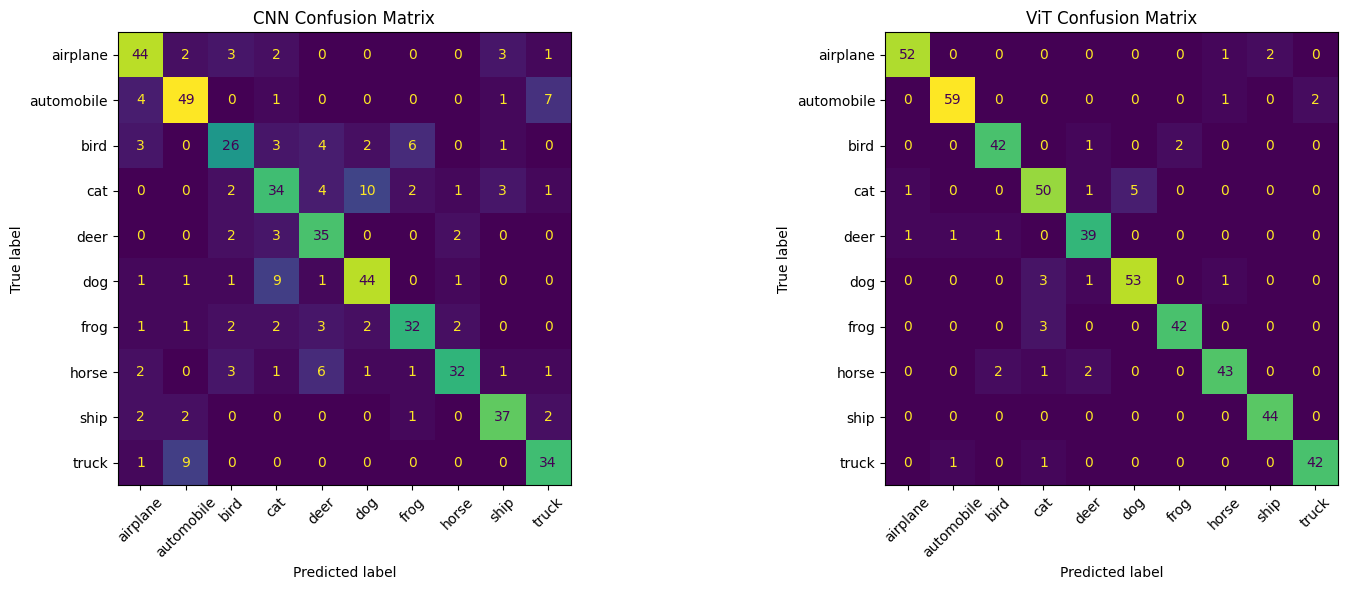

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay(
    confusion_matrix(cnn_labels, cnn_preds, labels=range(10)),
    display_labels=classes
).plot(ax=axes[0], xticks_rotation=45, colorbar=False)

axes[0].set_title("CNN Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(vit_labels, vit_preds, labels=range(10)),
    display_labels=classes
).plot(ax=axes[1], xticks_rotation=45, colorbar=False)

axes[1].set_title("ViT Confusion Matrix")

plt.tight_layout()
plt.show()

In [14]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["CNN (ResNet-18)", "Vision Transformer (ViT)"],
    "Test Accuracy (%)": [cnn_acc, vit_acc],
    "Training Time (seconds)": [cnn_time, vit_time]
})

print(results)
results.to_csv("dl_assignment_results.csv", index=False)

                      Model  Test Accuracy (%)  Training Time (seconds)
0           CNN (ResNet-18)               73.4                11.726984
1  Vision Transformer (ViT)               93.2               133.784420
